# Task 1

# Julia Szcześniak 264504
# Piotr Rybak 254861

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

In [2]:
column_names = ['Sex', 'Length', 'Diameter', 'Height', 'Whole Weight',
                'Shucked Weight', 'Viscera Weight', 'Shell Weight', 'Rings']

units = {
    'Length': '[mm]',
    'Diameter': '[mm]',
    'Height': '[mm]',
    'Whole Weight': '[g]',
    'Shucked Weight': '[g]',
    'Viscera Weight': '[g]',
    'Shell Weight': '[g]',
    'Rings': 'Number'
}

df = pd.read_csv('data.csv', names=column_names)

In [3]:
num_of_rows = len(df)

In [4]:
counts = df['Sex'].value_counts()
percentages = (counts/num_of_rows * 100).round(2)

sex_distribution = pd.DataFrame({
    'count': counts, 
    '%': percentages
})

sex_distribution = sex_distribution.rename(index={'M': 'Male', 'I': 'Infant', 'F': 'Female'})
sex_distribution = sex_distribution.loc[['Male', 'Infant', 'Female']]

sex_distribution

,count,%
Sex,,
Male,1528,36.58
Infant,1342,32.13
Female,1307,31.29


In [5]:
quantitative_var  = df.drop(columns=['Sex'])
quantitative_stats = quantitative_var.describe().T
quantitative_stats = quantitative_stats[['mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2)

quantitative_stats

,mean,std,min,25%,50%,75%,max
Length,0.52,0.12,0.08,0.45,0.55,0.62,0.82
Diameter,0.41,0.10,0.06,0.35,0.42,0.48,0.65
Height,0.14,0.04,0.00,0.12,0.14,0.16,1.13
Whole Weight,0.83,0.49,0.00,0.44,0.80,1.15,2.83
Shucked Weight,0.36,0.22,0.00,0.19,0.34,0.50,1.49
Viscera Weight,0.18,0.11,0.00,0.09,0.17,0.25,0.76
Shell Weight,0.24,0.14,0.00,0.13,0.23,0.33,1.00
Rings,9.93,3.22,1.00,8.00,9.00,11.00,29.00


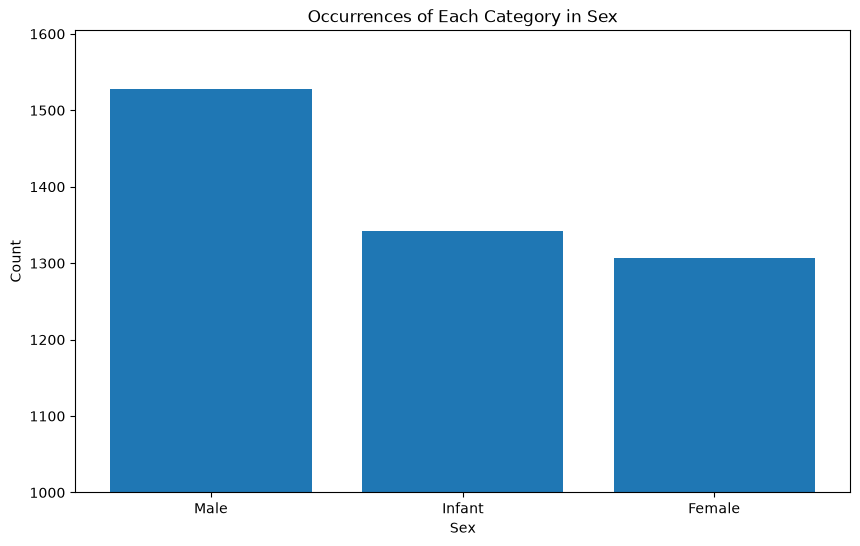

In [6]:
plt.figure(figsize=(10, 6))

plt.bar(
    sex_distribution.index, 
    sex_distribution['count'],
)
plt.title('Occurrences of Each Category in Sex')
plt.xlabel('Sex')
plt.ylabel('Count')

plt.ylim(bottom=1000)

plt.show()

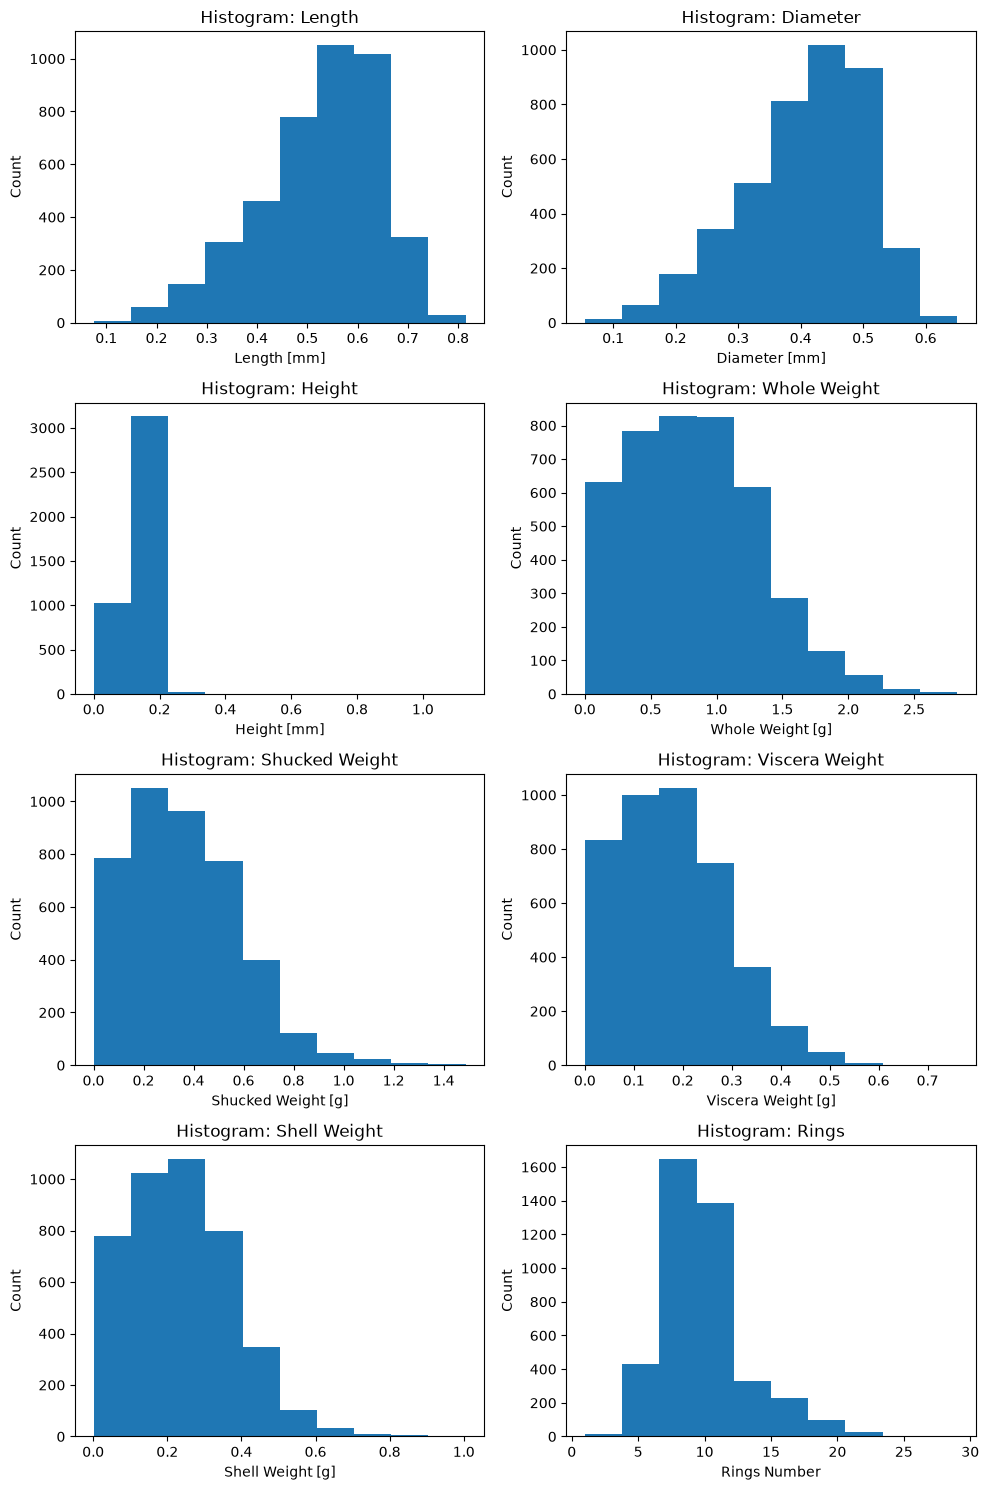

In [7]:
fig, axs = plt.subplots(4, 2, figsize=(10, 15))

for ax, col in zip(axs.flatten(), quantitative_var.columns):
    ax.hist(quantitative_var[col])
    ax.set_title(f'Histogram: {col}')
    ax.set_ylabel('Count')
    unit_str = units[col]
    ax.set_xlabel(f'{col} {unit_str}')

plt.tight_layout()
plt.show()

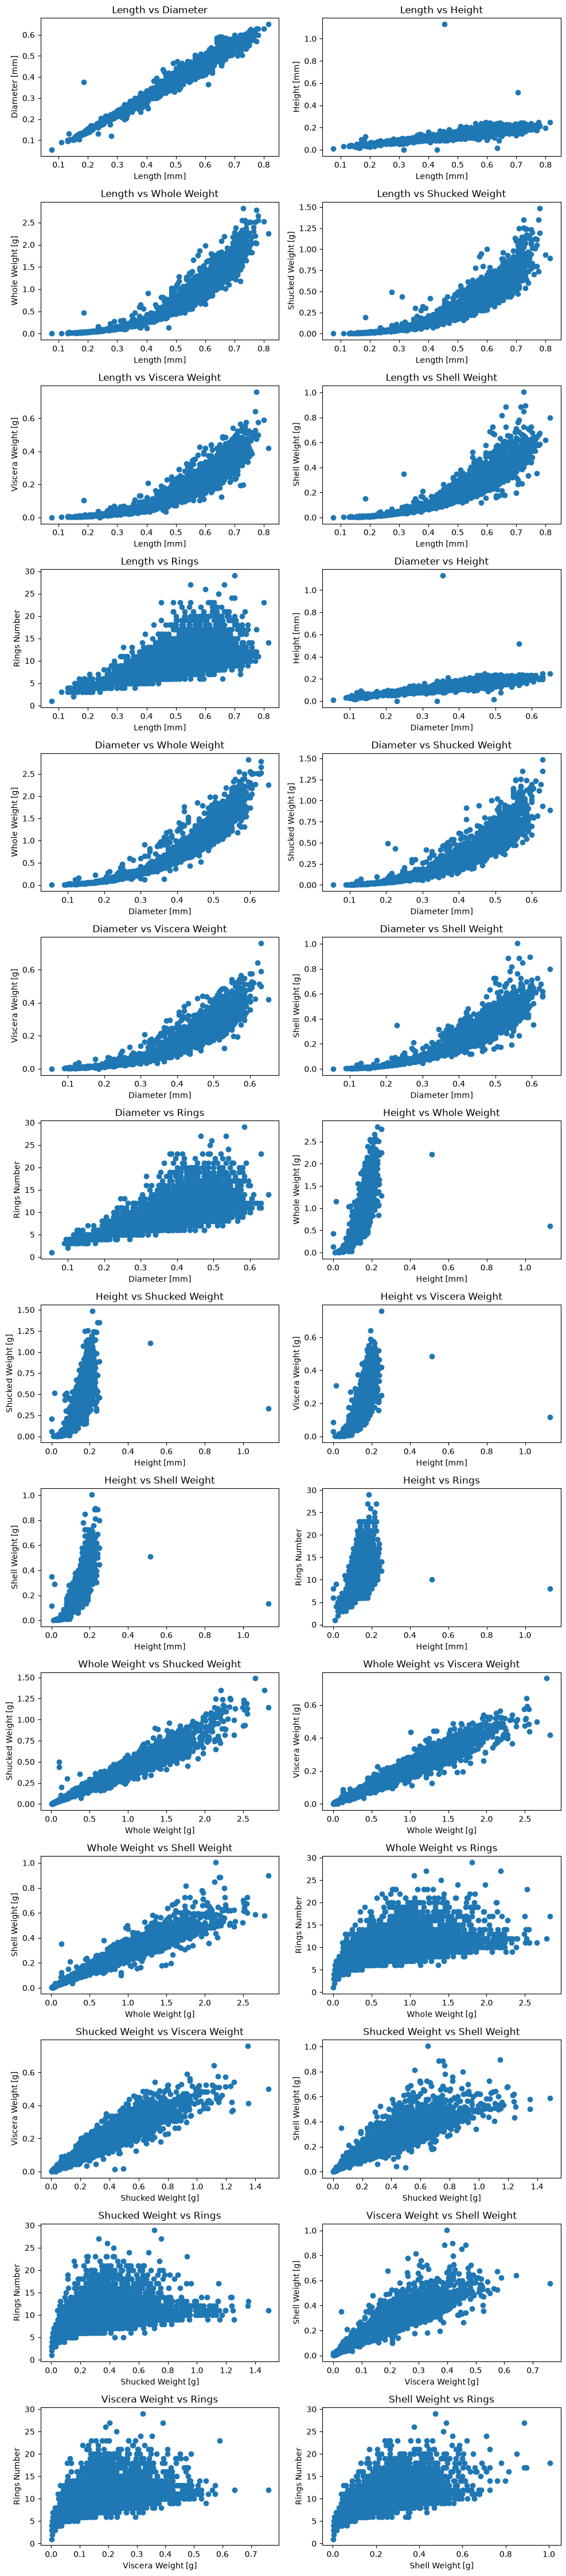

In [8]:
pairs = list(combinations(quantitative_var.columns, 2))

fig, axs = plt.subplots(14, 2, figsize=(10, 45))
for ax, (var1, var2) in zip(axs.flatten(), pairs):
    ax.scatter(quantitative_var[var1], quantitative_var[var2])
    ax.set_title(f'{var1} vs {var2}')
    unit_str_var1 = units[var1]
    unit_str_var2 = units[var2]
    ax.set_xlabel(f'{var1} {unit_str_var1}')
    ax.set_ylabel(f'{var2} {unit_str_var2}')

plt.tight_layout()
plt.show()

In [9]:
corr_matrix = quantitative_var.corr(method="pearson").round(2)

corr_matrix

,Length,Diameter,Height,Whole Weight,Shucked Weight,Viscera Weight,Shell Weight,Rings
Length,1.00,0.99,0.83,0.93,0.90,0.90,0.90,0.56
Diameter,0.99,1.00,0.83,0.93,0.89,0.90,0.91,0.57
Height,0.83,0.83,1.00,0.82,0.77,0.80,0.82,0.56
Whole Weight,0.93,0.93,0.82,1.00,0.97,0.97,0.96,0.54
Shucked Weight,0.90,0.89,0.77,0.97,1.00,0.93,0.88,0.42
Viscera Weight,0.90,0.90,0.80,0.97,0.93,1.00,0.91,0.50
Shell Weight,0.90,0.91,0.82,0.96,0.88,0.91,1.00,0.63
Rings,0.56,0.57,0.56,0.54,0.42,0.50,0.63,1.00


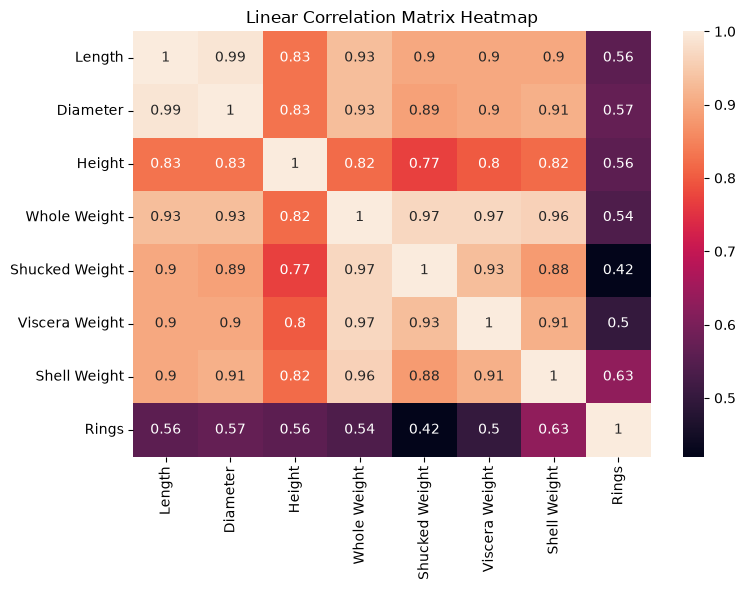

In [10]:
plt.figure(figsize=(8, 6))

sns.heatmap(corr_matrix, annot=True)

plt.title("Linear Correlation Matrix Heatmap")
plt.tight_layout()

plt.show()

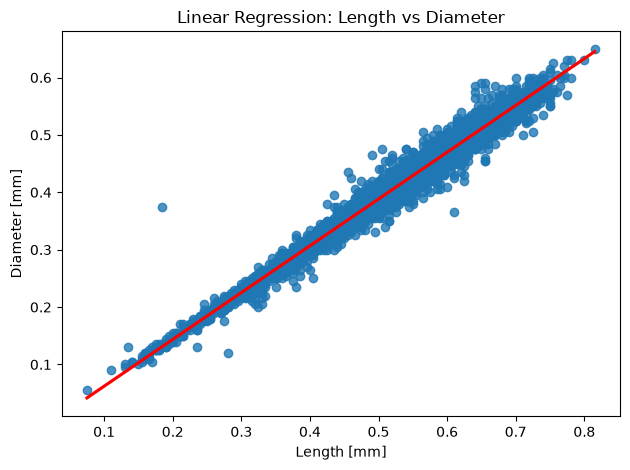

In [11]:
sns.regplot(data=quantitative_var, x='Length', y='Diameter', line_kws=dict(color="r"))

plt.xlabel('Length [mm]')
plt.ylabel('Diameter [mm]')
plt.title('Linear Regression: Length vs Diameter')

plt.tight_layout()
plt.show()